### II. PCA com NumPy

A PCA foi aplicada a **10 variáveis numéricas** após a **centralização na média** dos dados, um passo crucial para garantir que a análise não seja dominada pelas escalas absolutas das variáveis.

**Objetivo:** Segmentar o conjunto de dados populacionais em grupos (clusters) que compartilham características similares, utilizando o algoritmo K-Means.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
import warnings
warnings.filterwarnings('ignore')

In [2]:
df_uf = pd.read_csv('../data/censo2022/dados_demograficos_uf.csv')
df_municipios = pd.read_excel('../data/censo2022/br_ibge_censo_2022_municipio.xlsx')

In [3]:
# Groupby para UF's
df_municipios_uf = df_municipios.groupby('sigla_uf').agg({
    'populacao': 'sum',
    'domicilios': 'sum', 
    'area': 'sum',
    'taxa_alfabetizacao': 'mean',
    'razao_sexo': 'mean',
    'populacao_indigena': 'sum',
    'populacao_quilombola': 'sum'
}).reset_index()

# Densidade demográfica
df_municipios_uf['densidade_demografica'] = df_municipios_uf['populacao'] / df_municipios_uf['area']

# Merge por UF
df_completo = pd.merge(df_uf, df_municipios_uf, on='sigla_uf', how='inner')

# Colunas numéricas
colunas_numericas = [
    'idade_mediana', 'indice_envelhecimento', 'populacao', 
    'domicilios', 'area', 'taxa_alfabetizacao', 'razao_sexo',
    'populacao_indigena', 'populacao_quilombola', 'densidade_demografica'
]

colunas_disponiveis = [col for col in colunas_numericas if col in df_completo.columns]

# Preencher valores nulos
for coluna in colunas_disponiveis:
    if df_completo[coluna].isna().sum() > 0:
        df_completo[coluna] = df_completo[coluna].fillna(df_completo[coluna].mean())

# Criar matriz X
X = df_completo[colunas_disponiveis].values

# Padronizar
scaler = StandardScaler()
X_padronizado = scaler.fit_transform(X)


In [4]:
# K-IDEAL
# Método do Cotovelo

inertias = []
k_range = range(1, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_padronizado)
    inertias.append(kmeans.inertia_)

In [5]:
# Método da Silhueta
silhouette_scores = []
for k in range(2, 11):  # Silhueta não funciona para k=1
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    cluster_labels = kmeans.fit_predict(X_padronizado)
    silhouette_avg = silhouette_score(X_padronizado, cluster_labels)
    silhouette_scores.append(silhouette_avg)

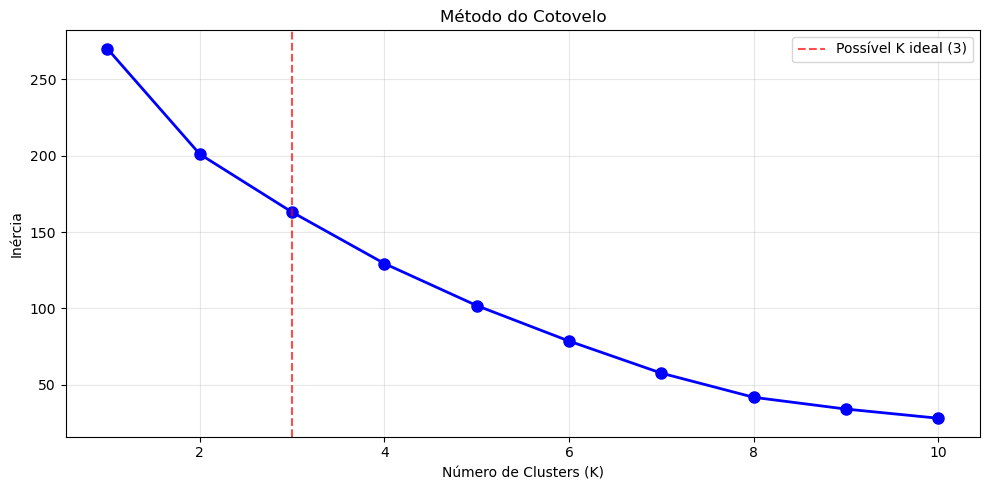

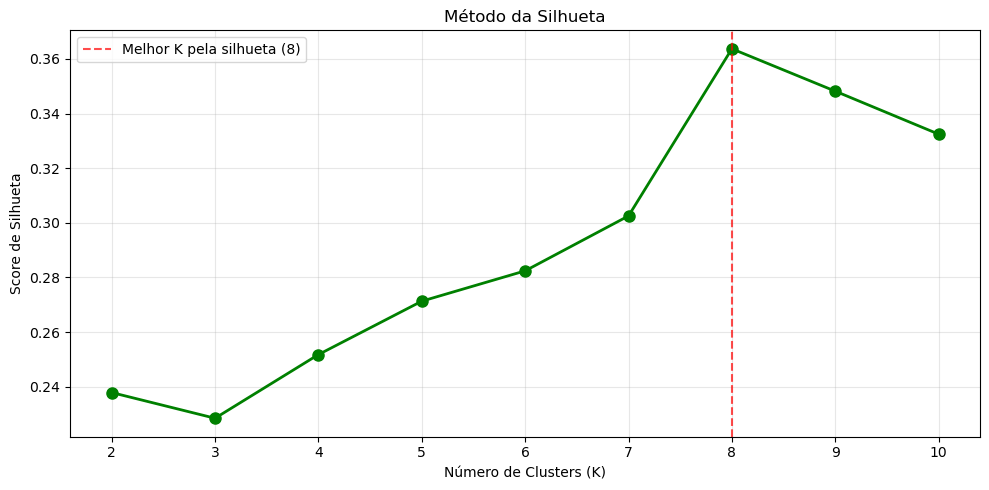

In [6]:
# Gráfico Cotovelo
plt.figure(figsize=(10, 5))

plt.plot(k_range, inertias, 'bo-', linewidth=2, markersize=8)
plt.xlabel('Número de Clusters (K)')
plt.ylabel('Inércia')
plt.title('Método do Cotovelo')
plt.grid(True, alpha=0.3)
plt.axvline(x=3, color='red', linestyle='--', alpha=0.7, label='Possível K ideal (3)')
plt.legend()
plt.tight_layout()

plt.savefig('../resultados/analise_k_cotovelo.png', dpi=300, bbox_inches='tight')
plt.show()

# Gráfico Silhueta
plt.figure(figsize=(10, 5))

plt.plot(range(2, 11), silhouette_scores, 'go-', linewidth=2, markersize=8)
plt.xlabel('Número de Clusters (K)')
plt.ylabel('Score de Silhueta')
plt.title('Método da Silhueta')
plt.grid(True, alpha=0.3)

melhor_k_silhueta = range(2, 11)[np.argmax(silhouette_scores)]
plt.axvline(x=melhor_k_silhueta, color='red', linestyle='--', alpha=0.7, 
            label=f'Melhor K pela silhueta ({melhor_k_silhueta})')
plt.legend()
plt.tight_layout()

plt.savefig('../resultados/analise_k_silhueta.png', dpi=300, bbox_inches='tight')
plt.show()

In [7]:
k_ideal_cotovelo = 3
k_ideal_silhueta = melhor_k_silhueta

print(f"\nK ideal pelo método do cotovelo: {k_ideal_cotovelo}")
print(f"K ideal pelo método da silhueta: {k_ideal_silhueta}")
print(f"Scores de silhueta: {dict(zip(range(2, 11), [f'{s:.3f}' for s in silhouette_scores]))}")

if silhouette_scores[k_ideal_silhueta-2] > 0.5:
    k_final = k_ideal_silhueta
    print(f"K final escolhido: {k_final} (baseado no método da silhueta)")
else:
    k_final = k_ideal_cotovelo
    print(f"K final escolhido: {k_final} (baseado no método do cotovelo)")


K ideal pelo método do cotovelo: 3
K ideal pelo método da silhueta: 8
Scores de silhueta: {2: '0.238', 3: '0.228', 4: '0.252', 5: '0.271', 6: '0.282', 7: '0.303', 8: '0.364', 9: '0.348', 10: '0.332'}
K final escolhido: 3 (baseado no método do cotovelo)


In [8]:
# TREINAMENTO
kmeans = KMeans(n_clusters=k_final, random_state=42, n_init=15)
cluster_labels = kmeans.fit_predict(X_padronizado)

df_completo['cluster'] = cluster_labels
df_completo['cluster'] = df_completo['cluster'].astype(str)

Variância explicada pelos componentes PCA: PC1=39.12%, PC2=21.83%


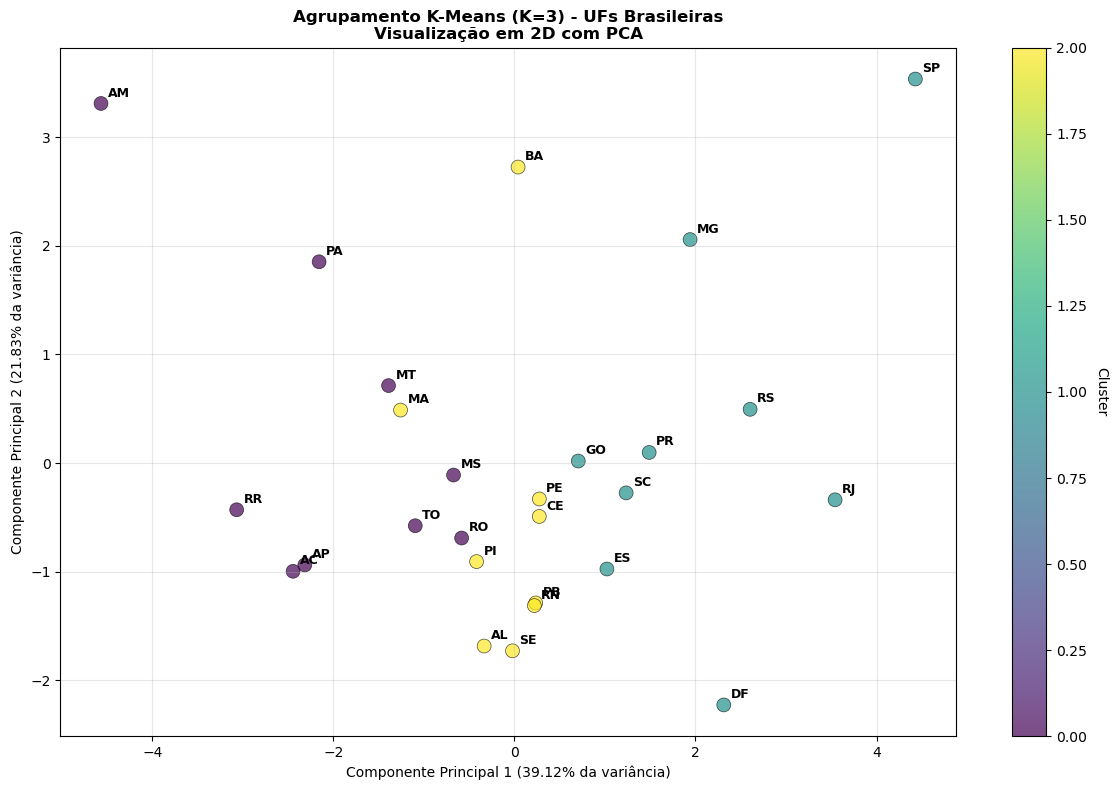

In [9]:
# VISUALIZACAO DOS CLUSTERS
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_padronizado)

df_completo['PC1'] = X_pca[:, 0]
df_completo['PC2'] = X_pca[:, 1]

variancia_explicada = pca.explained_variance_ratio_
print(f"Variância explicada pelos componentes PCA: PC1={variancia_explicada[0]:.2%}, PC2={variancia_explicada[1]:.2%}")


plt.figure(figsize=(12, 8))

scatter = plt.scatter(df_completo['PC1'], df_completo['PC2'], 
                     c=df_completo['cluster'].astype('category').cat.codes, 
                     cmap='viridis', s=100, alpha=0.7, edgecolors='black', linewidth=0.5)

for i, row in df_completo.iterrows():
    plt.annotate(row['sigla_uf'], (row['PC1'], row['PC2']), 
                xytext=(5, 5), textcoords='offset points', 
                fontsize=9, fontweight='bold')

plt.xlabel(f'Componente Principal 1 ({variancia_explicada[0]:.2%} da variância)')
plt.ylabel(f'Componente Principal 2 ({variancia_explicada[1]:.2%} da variância)')
plt.title(f'Agrupamento K-Means (K={k_final}) - UFs Brasileiras\nVisualização em 2D com PCA', fontweight='bold')

cbar = plt.colorbar(scatter)
cbar.set_label('Cluster', rotation=270, labelpad=15)

plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(f'../resultados/kmeans_clusters_k{k_final}.png', dpi=300, bbox_inches='tight')
plt.show()


In [10]:
print("\nESTATÍSTICAS POR CLUSTER (valores médios):")
cluster_stats = df_completo.groupby('cluster')[colunas_disponiveis].mean()

# Exibir estatísticas formatadas
for col in colunas_disponiveis:
    cluster_stats[col] = cluster_stats[col].round(2)

print(cluster_stats)


ESTATÍSTICAS POR CLUSTER (valores médios):
         idade_mediana  indice_envelhecimento    populacao  domicilios  \
cluster                                                                  
0                28.59                  30.57   2627429.89   832290.00   
1                37.18                  71.76  13772210.33  5130134.11   
2                32.77                  50.55   6054028.67  2088283.44   

              area  taxa_alfabetizacao  razao_sexo  populacao_indigena  \
cluster                                                                  
0        567882.56                0.89      105.43           102424.00   
1        203799.89                0.94       98.53            25316.89   
2        172465.67                0.79       98.25            58210.00   

         populacao_quilombola  densidade_demografica  
cluster                                               
0                    20142.11                   5.07  
1                    26460.78                 149

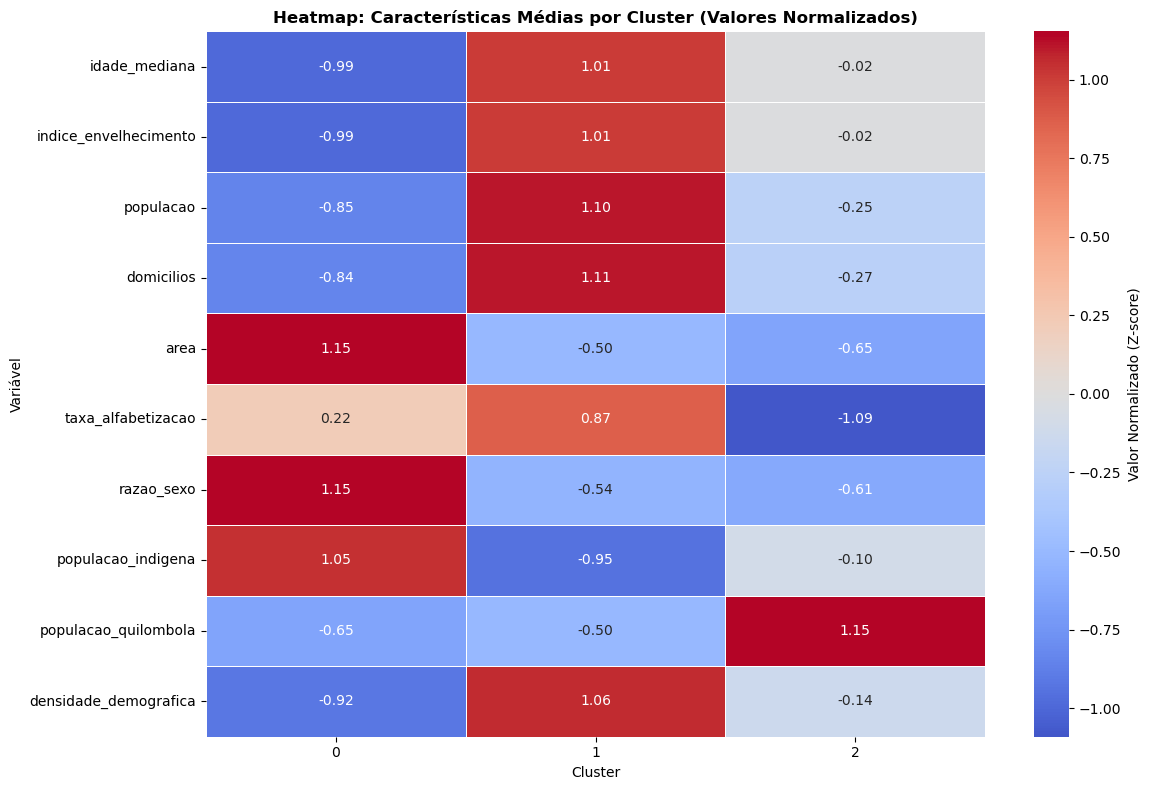

In [11]:
cluster_stats_normalized = (cluster_stats - cluster_stats.mean()) / cluster_stats.std()

plt.figure(figsize=(12, 8))
sns.heatmap(cluster_stats_normalized.T, annot=True, cmap='coolwarm', center=0,
            fmt='.2f', linewidths=0.5, cbar_kws={'label': 'Valor Normalizado (Z-score)'})
plt.title('Heatmap: Características Médias por Cluster (Valores Normalizados)', fontweight='bold')
plt.xlabel('Cluster')
plt.ylabel('Variável')
plt.tight_layout()
plt.savefig('../resultados/heatmap_clusters.png', dpi=300, bbox_inches='tight')
plt.show()

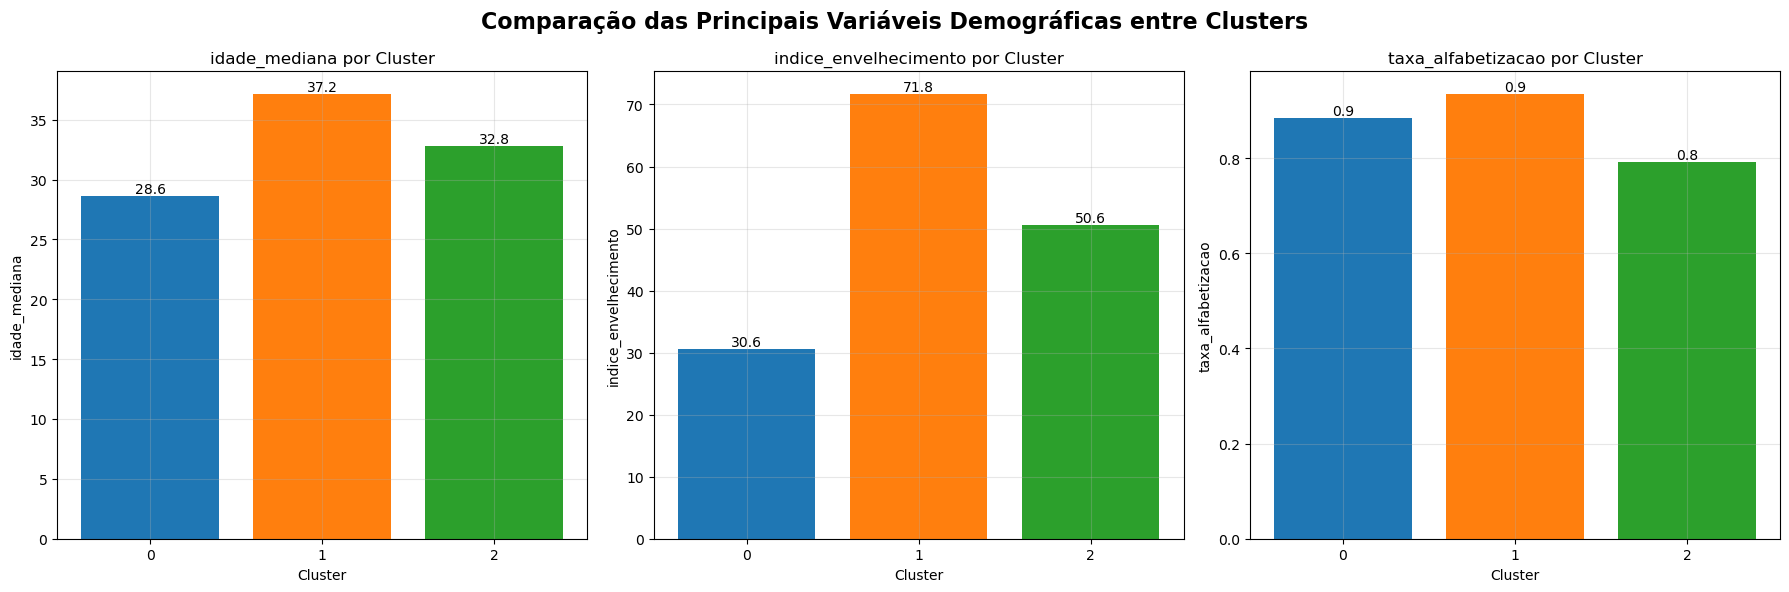

In [12]:
variaveis_comparacao = ['idade_mediana', 'indice_envelhecimento', 'taxa_alfabetizacao']
n_variaveis = len(variaveis_comparacao)

fig, axes = plt.subplots(1, n_variaveis, figsize=(18, 6))

for i, var in enumerate(variaveis_comparacao):
    dados_plot = df_completo.groupby('cluster')[var].mean()
    bars = axes[i].bar(dados_plot.index, dados_plot.values, color=['#1f77b4', '#ff7f0e', '#2ca02c'][:len(dados_plot)])
    axes[i].set_title(f'{var} por Cluster')
    axes[i].set_xlabel('Cluster')
    axes[i].set_ylabel(var)
    axes[i].grid(True, alpha=0.3)
    
    for bar in bars:
        height = bar.get_height()
        axes[i].text(bar.get_x() + bar.get_width()/2., height,
                    f'{height:.1f}', ha='center', va='bottom')

plt.suptitle('Comparação das Principais Variáveis Demográficas entre Clusters', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('../resultados/comparacao_final_clusters.png', dpi=300, bbox_inches='tight')
plt.show()

In [13]:
# Calcular diferenças em relação à média geral
media_geral = df_completo[colunas_disponiveis].mean()
diferencas = cluster_stats - media_geral

print("\nCARACTERÍSTICAS PRINCIPAIS DE CADA CLUSTER (diferenças em relação à média geral):")

for cluster in cluster_stats.index:
    print(f"\n--- CLUSTER {cluster} ({len(df_completo[df_completo['cluster'] == cluster])} UFs) ---")
    
    caracteristicas_positivas = diferencas.loc[cluster].nlargest(3)
    caracteristicas_negativas = diferencas.loc[cluster].nsmallest(3)
    
    print("Características ACIMA da média:")
    for var, valor in caracteristicas_positivas.items():
        if valor > 0:
            print(f"  • {var}: +{valor:.2f}")
    
    print("Características ABAIXO da média:")
    for var, valor in caracteristicas_negativas.items():
        if valor < 0:
            print(f"  • {var}: {valor:.2f}")
    
    ufs_cluster = df_completo[df_completo['cluster'] == cluster]['sigla_uf'].tolist()
    print(f"UFs no cluster: {', '.join(ufs_cluster)}")


CARACTERÍSTICAS PRINCIPAIS DE CADA CLUSTER (diferenças em relação à média geral):

--- CLUSTER 0 (9 UFs) ---
Características ACIMA da média:
  • area: +253166.52
  • populacao_indigena: +40440.37
  • razao_sexo: +4.69
Características ABAIXO da média:
  • populacao: -4857126.41
  • domicilios: -1851279.19
  • populacao_quilombola: -28487.11
UFs no cluster: AC, AM, AP, MS, MT, PA, RO, RR, TO

--- CLUSTER 1 (9 UFs) ---
Características ACIMA da média:
  • populacao: +6287654.03
  • domicilios: +2446564.92
  • densidade_demografica: +77.25
Características ABAIXO da média:
  • area: -110916.15
  • populacao_indigena: -36666.74
  • populacao_quilombola: -22168.44
UFs no cluster: DF, ES, GO, MG, PR, RJ, RS, SC, SP

--- CLUSTER 2 (9 UFs) ---
Características ACIMA da média:
  • populacao_quilombola: +50655.56
Características ABAIXO da média:
  • populacao: -1430527.63
  • domicilios: -595285.75
  • area: -142250.37
UFs no cluster: AL, BA, CE, MA, PB, PE, PI, RN, SE
